# Kesit İstatistik — İleri regresyon modelleri

Kurulum: `python -m pip install -r requirements.txt`

Python 3.11+ ve Jupyter/VS Code ile aç. Önce kurulum hücresini, sonra ders hücrelerini çalıştır. Hazır çıktılar doğrulanan çalıştırmadan alınmıştır; kodu değiştirdiğinde hücreyi yeniden çalıştır. Her ders kendi sentetik verisini üretir. İnternet/API/şirket verisi gerektirmez.


## Etkileşimler ve polinom regresyon

İş yükü etkisi vardiyaya göre değişiyor mu?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** İki vardiya doğrusunun farklı eğimlerini karşılaştır.

**Yorum sınırı:** Etkileşim koşullu ilişkiyi gösterir; randomizasyon olmadan nedensellik kurulmaz.

**Alıştırma:** Etkileşim katsayısını 1.2’den 0’a indir; modelde ve grafikte ne değiştiğini yaz.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


Intercept    2.548
x            2.561
vardiya      1.956
x:vardiya    1.231
I(x ** 2)    0.097
dtype: float64
Etkileşim CI: [1.017, 1.446]


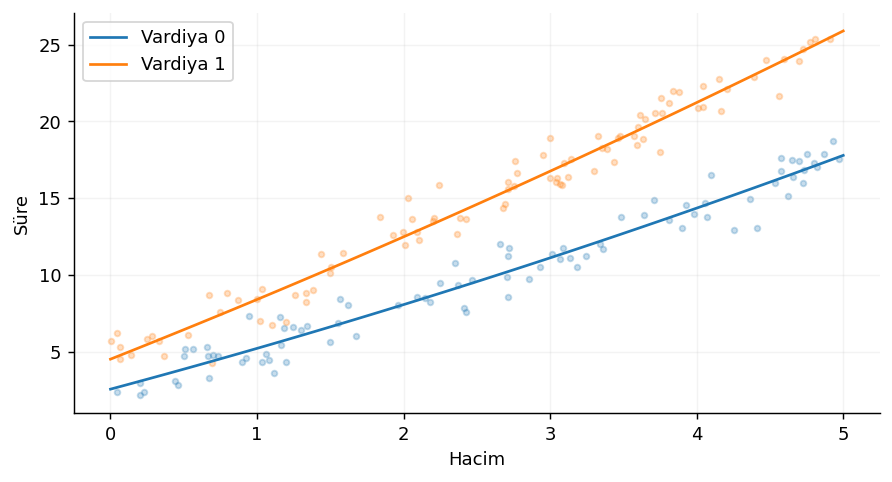

In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

x=rng.uniform(0,5,180);shift=rng.integers(0,2,180);y=3+2*x+2*shift+1.2*x*shift+.2*x*x+rng.normal(0,1,180);d=pd.DataFrame({'x':x,'vardiya':shift,'y':y});fit=smf.ols('y ~ x * vardiya + I(x**2)',d).fit();print(fit.params.round(3));print('Etkileşim CI:',fit.conf_int().loc['x:vardiya'].round(3).tolist())
for g in [0,1]:
 xx=np.linspace(0,5,80);plt.scatter(x[shift==g],y[shift==g],s=10,alpha=.25);plt.plot(xx,fit.predict(pd.DataFrame({'x':xx,'vardiya':g})),label=f'Vardiya {g}')
plt.xlabel('Hacim');plt.ylabel('Süre');plt.legend()

## Poisson, negatif binom ve maruziyet

Daha uzun maruziyet daha çok hatayı açıklıyor mu?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Aynı x için sayım yerine maruziyet başına oranı karşılaştır.

**Yorum sınırı:** Offset log(maruziyet) katsayısı 1’e sabittir. Negatif binom modeli aşırı saçılma için ayrıca gerekçelendirilir.

**Alıştırma:** Maruziyetleri iki katına çıkar; oran ile beklenen sayımı ayır.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'Poisson_beta': [0.5426040288889732, 0.6184653966642888], 'NB_beta_ve_alpha': [0.547243668326864, 0.6052450989344944, 0.3736596116198779], 'Poisson_Pearson_dispersion': np.float64(2.32491160034765)}


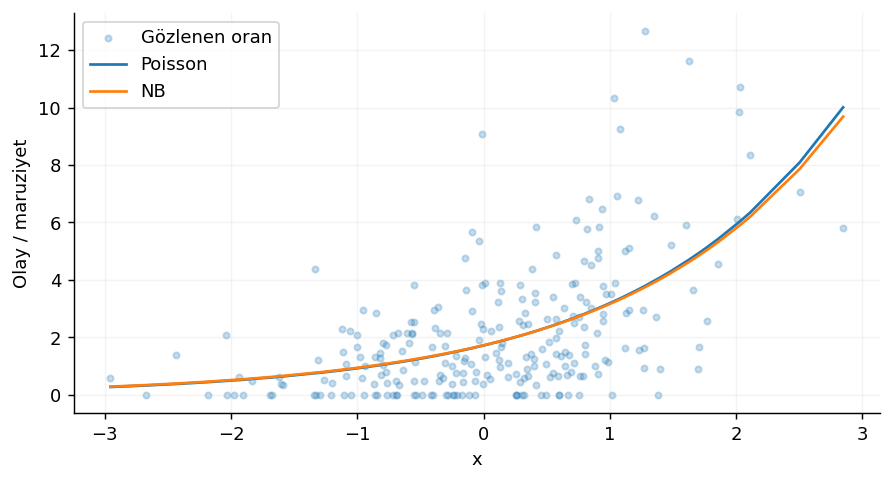

In [70]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

x=rng.normal(size=250);exposure=rng.uniform(.5,3,250);mu=exposure*np.exp(.5+.6*x);y=rng.negative_binomial(3,3/(3+mu));X=sm.add_constant(x)
pois=sm.GLM(y,X,family=sm.families.Poisson(),offset=np.log(exposure)).fit();nb=sm.NegativeBinomial(y,X,offset=np.log(exposure)).fit(disp=False)
print({'Poisson_beta':pois.params.tolist(),'NB_beta_ve_alpha':nb.params.tolist(),'Poisson_Pearson_dispersion':pois.pearson_chi2/pois.df_resid})
order=np.argsort(x);plt.scatter(x,y/exposure,s=12,alpha=.25,label='Gözlenen oran');plt.plot(x[order],np.exp(X@pois.params)[order],label='Poisson');plt.plot(x[order],np.exp(X@nb.params[:2])[order],label='NB');plt.xlabel('x');plt.ylabel('Olay / maruziyet');plt.legend()

## Karma etkili modeller ve kısmi havuzlama

Az kayıtlı deponun ortalamasına ne kadar güvenmeliyim?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Ham grup ortalamalarıyla karma model tahminlerini karşılaştır.

**Yorum sınırı:** Rastgele kesişim modeli grupların ortak dağılımını varsayar; ML/REML ve grup tasarımı önemlidir.

**Alıştırma:** İlk deponun n değerini 5’ten 50’ye çıkar; küçültmenin nasıl değiştiğini incele.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'genel_ortalama': 10.379004704382114, 'grup_varyansi': 2.192024162969332, 'hata_varyansi': 7.739394878555071}


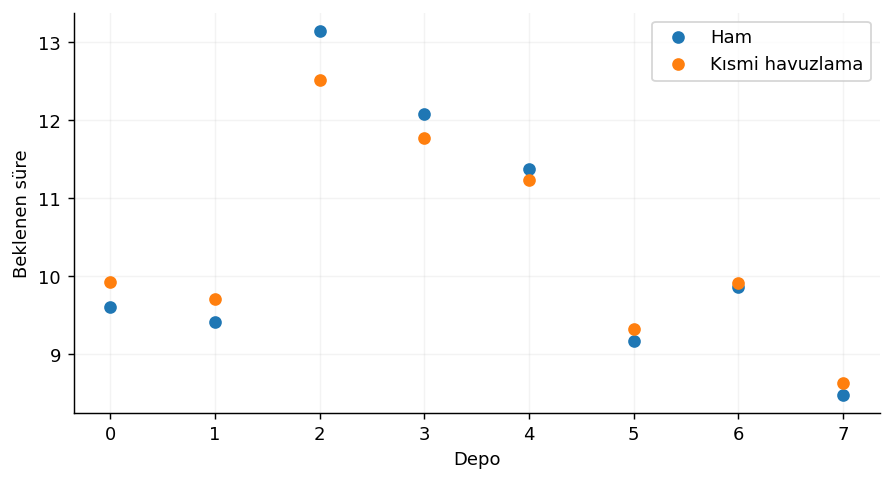

In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

rows=[]
for g,n in enumerate([5,8,12,16,20,24,30,40]):
 u=rng.normal(0,2)
 for j in range(n):rows.append([str(g),10+u+rng.normal(0,3)])
d=pd.DataFrame(rows,columns=['depo','sure']);fit=smf.mixedlm('sure ~ 1',d,groups=d.depo).fit(reml=True,method='powell',disp=False);raw=d.groupby('depo').sure.mean();pooled=np.array([fit.fe_params.iloc[0]+float(fit.random_effects[g].iloc[0]) for g in raw.index]);print({'genel_ortalama':float(fit.fe_params.iloc[0]),'grup_varyansi':float(fit.cov_re.iloc[0,0]),'hata_varyansi':float(fit.scale)})
plt.plot(raw.index,raw,'o',label='Ham');plt.plot(raw.index,pooled,'o',label='Kısmi havuzlama');plt.xlabel('Depo');plt.ylabel('Beklenen süre');plt.legend()

## Kantil regresyon ve esnek eğriler

Ortalama süre iyi görünürken üst hizmet kuyruğu ne oluyor?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Koşullu medyan ve .9 kantil çizgisini aynı noktalarda oku.

**Yorum sınırı:** Kantil katsayısı koşullu kantile aittir; nedensellik veya tekil tahmin garantisi değildir.

**Alıştırma:** Hata ölçeğinin x ile artışını kaldır; kantil eğimlerinin değişimini açıkla.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


Kantil 0.5 katsayılar [4.825 2.131]
Kantil 0.9 katsayılar [5.88  2.817]


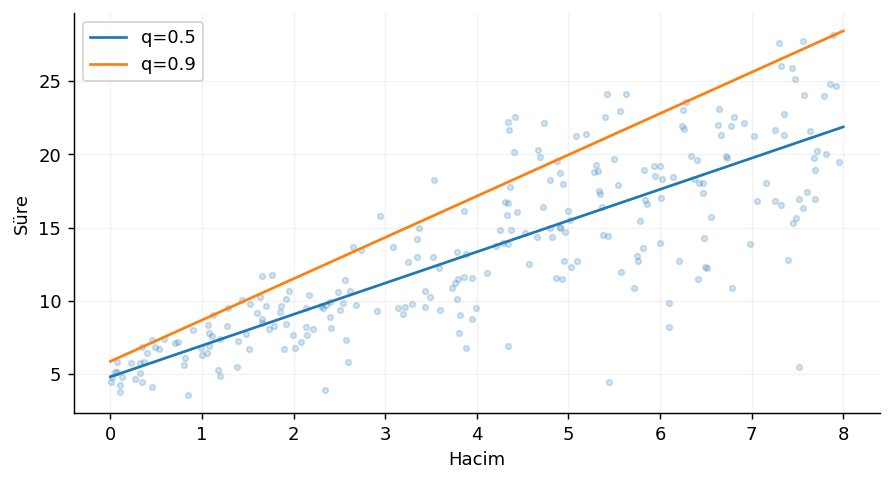

In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

x=rng.uniform(0,8,250);y=5+2*x+rng.normal(size=len(x))*(1+.5*x);X=sm.add_constant(x);grid=np.linspace(0,8,100)
for q in [.5,.9]:
 fit=sm.QuantReg(y,X).fit(q=q,max_iter=3000);print('Kantil',q,'katsayılar',fit.params.round(3));plt.plot(grid,fit.predict(sm.add_constant(grid)),label=f'q={q}')
plt.scatter(x,y,s=10,alpha=.2);plt.xlabel('Hacim');plt.ylabel('Süre');plt.legend()